# 06 — Multiplexador e demultiplexador WDM

Este notebook segue a aula (`docs/04-class/context.md`, "MUX E DEMUX") e o guia
`docs/mux_demux.md`.

Regras usadas em todas as figuras (as mesmas dos notebooks anteriores):

- a física simulada vem **sempre** do pacote (`simcopy.kernels.wdm`); o notebook só escreve as
  formas fechadas, que são a referência;
- as asserções numéricas ficam nos testes do pytest, escritos pelo grupo.

Fontes: Agrawal, *Sistemas de Comunicação por Fibra Óptica*, 4ª ed., seções 6.2.2 e 6.3.1, o
código do professor (`draft.py`: soma dos canais e `optical_filter`), o VPI (`WDM_MUX_N_1`,
`FilterOpt`) e a arquitetura (P-8, C-11, C-20). O texto separa **fato** de **dedução**.

**Ainda não há blocos** `Multiplexer` e `Demultiplexer`: a configuração depende das dúvidas do
guia. Aqui só o kernel.

## 0. Modelo

**[Fato: `draft.py`, linhas 2016–2047]** O mux do professor é a soma dos campos dos canais,
cada um já deslocado em frequência pelo próprio laser (`Freq_offset` em $\pm\delta f/2$ e
$\pm3\delta f/2$, δf = 75 GHz). **[Fato: `draft.py`, linha 2058]** O demux é `optical_filter`,
uma máscara retangular na FFT centrada no canal.

**[Fato: Agrawal, seção 6.2.2]** Mux e demux são o mesmo tipo de dispositivo (grades de
difração ou filtros de interferência), usado nos dois sentidos. **[Fato: Agrawal, Eq. 6.3.1 e
6.3.4]** Com o filtro ajustado no canal m, chega ao detector $P = P_m + \sum_{n\ne m}T_{mn}P_n$,
com $T_{mn}$ a transmitância do filtro para o canal n; a penalidade de potência é
$\delta_X \approx 10\log_{10}(1 + X)$, $X = \sum_{n\ne m}T_{mn}$.

**[Fato: VPI]** O mux (`WDM_MUX_N_1`) tem perda de 3 dB e filtro passa-banda "Gaussian" de
ordem 3 e 70 GHz por canal; o filtro de seleção do receptor (`FilterOpt`) também, 70 GHz.
**[Fato: arquitetura]** A máscara retangular tem resposta ao impulso tipo sinc, com *ringing*
(P-8); a correção proposta é um filtro suave, supergaussiano ou Butterworth (C-11).

O kernel `bandpass_response` tem a máscara retangular do professor e a supergaussiana
$H(f) = \exp[-\tfrac{\ln 2}{2}(2(f - f_c)/B)^{2n}]$, com $|H|^2 = 1/2$ nas bordas (n = 1 é a
gaussiana). **[Proposta]** É a minha leitura do "Gaussian de ordem 3" do VPI, a confirmar.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from simcopy.kernels.wdm import multiplex, frequency_shift, bandpass_response, apply_optical_filter
from simcopy.config.system import (SystemConfig, CoherentChannel, LinkConfig, SpanConfig,
                                   FiberConfig)
from simcopy.core.grid import TimeGrid

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True,
                     "grid.alpha": 0.3, "legend.fontsize": 7.5})
C4 = ["tab:blue", "tab:orange", "tab:green", "tab:red"]

RS, RHO = 50e9, 0.2                                 # 50 GBd, cosseno levantado com roll-off 0,2
SISTEMA = SystemConfig(channels=tuple(CoherentChannel(index=i, symbol_rate=RS, seed=i) for i in range(4)),
                       link=LinkConfig(spans=(SpanConfig(FiberConfig(1e3)),)), channel_spacing=75e9)
OFFS = np.array(SISTEMA.channel_offsets())           # desvios dos canais [Hz], da configuração
FS, N = 600e9, 2 ** 16                               # bins de 9,155 MHz: 37,5 GHz = 4096 bins
grade = TimeGrid(FS, N)
t, f = grade.time, grade.freq

def espectro_rc(freq):
    """Espectro de cosseno levantado (não a raiz): o canal ocupa |f| ≤ (1 + ρ)R_s/2 = 30 GHz."""
    a = np.abs(freq)
    f1, f2 = (1 - RHO) * RS / 2, (1 + RHO) * RS / 2
    H = np.where(a <= f1, 1.0, 0.0)
    m = (a > f1) & (a <= f2)
    H[m] = 0.5 * (1 + np.cos(np.pi / (RHO * RS) * (a[m] - f1)))
    return H

def canal(seed, potencia=1e-3):
    """Canal QPSK sintético em banda base, 1 mW, na polarização X (ainda não há formatador de pulso)."""
    r = np.random.default_rng(seed)
    simb = r.choice([-1, 1], N) + 1j * r.choice([-1, 1], N)
    x = np.fft.ifft(np.fft.fft(simb) * espectro_rc(f))
    out = np.zeros((2, N), dtype=complex)
    out[0] = x * np.sqrt(potencia / np.mean(np.abs(x) ** 2))
    return out

CANAIS = [canal(s) for s in range(4)]
WDM = multiplex(CANAIS, OFFS, t)
print("desvios da grade (SystemConfig.channel_offsets):", OFFS / 1e9, "GHz")
print(f"potência total do campo agregado: {np.sum(np.mean(np.abs(WDM)**2, axis=1))*1e3:.3f} mW (4 × 1 mW)")

desvios da grade (SystemConfig.channel_offsets): [-112.5  -37.5   37.5  112.5] GHz
potência total do campo agregado: 4.000 mW (4 × 1 mW)


## 1. A grade WDM e os filtros

Quatro canais de 50 GBd espaçados de 75 GHz, como no cenário 400ZR (a grade vem de
`SystemConfig.channel_offsets()`). Os filtros de demux comparados: a máscara retangular do
professor com 75 GHz e a supergaussiana de 70 GHz, de ordens 1 (gaussiana) e 3.

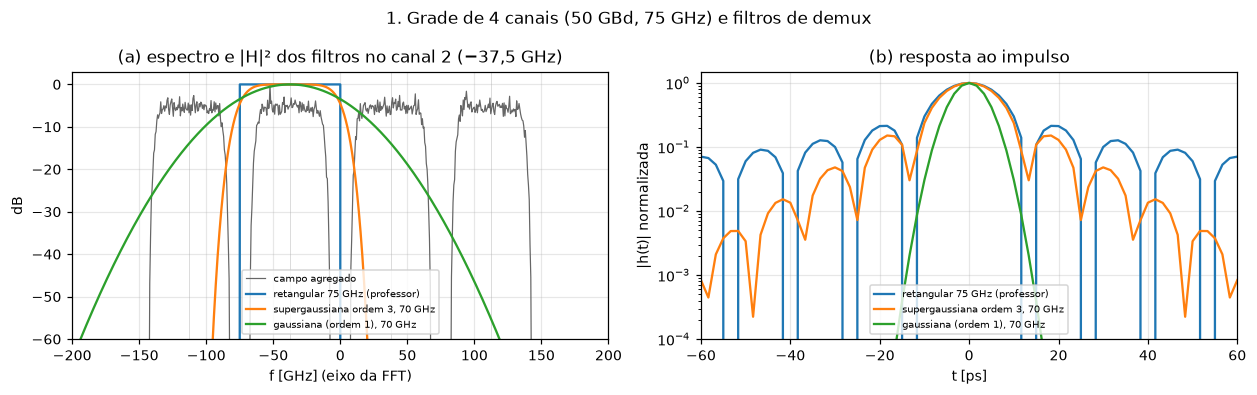

In [2]:
filtros = {"retangular 75 GHz (professor)": ("rectangular", 75e9, 1),
           "supergaussiana ordem 3, 70 GHz": ("supergaussian", 70e9, 3),
           "gaussiana (ordem 1), 70 GHz": ("supergaussian", 70e9, 1)}
fs_ = np.fft.fftshift(f)
S = np.fft.fftshift(np.sum(np.abs(np.fft.fft(WDM, axis=1)) ** 2, axis=0))
S_db = 10 * np.log10(S / S.max() + 1e-30)
blocos = S_db.reshape(-1, 64).max(axis=1)
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.6))
ax[0].plot(fs_.reshape(-1, 64).mean(axis=1) / 1e9, blocos, color="0.4", lw=0.8, label="campo agregado")
for i, (nome, (kind, Bf, n)) in enumerate(filtros.items()):
    H = np.fft.fftshift(bandpass_response(f, OFFS[1], Bf, kind, n))
    ax[0].plot(fs_ / 1e9, 10 * np.log10(np.abs(H) ** 2 + 1e-30), color=C4[i], label=nome)
    h = np.fft.fftshift(np.fft.ifft(bandpass_response(f, 0.0, Bf, kind, n)))
    ax[1].plot((t - t[N // 2]) * 1e12, np.abs(h) / np.abs(h).max(), color=C4[i], label=nome)
for o in OFFS:
    ax[0].axvline(o / 1e9, color="0.85", lw=0.6, zorder=0)
ax[0].set(xlim=(-200, 200), ylim=(-60, 3), xlabel="f [GHz] (eixo da FFT)", ylabel="dB",
          title="(a) espectro e |H|² dos filtros no canal 2 (−37,5 GHz)")
ax[1].set(xlim=(-60, 60), yscale="log", ylim=(1e-4, 1.5), xlabel="t [ps]",
          ylabel="|h(t)| normalizada", title="(b) resposta ao impulso")
for a_ in ax: a_.legend(fontsize=6.5, loc="lower center")
fig.suptitle("1. Grade de 4 canais (50 GBd, 75 GHz) e filtros de demux")
fig.tight_layout()

**Leitura.** (a) Cada canal ocupa 60 GHz ((1 + ρ)·50 GBd) dentro de 75 GHz, com 15 GHz de
guarda. A máscara retangular corta exatamente na borda do canal; a gaussiana de 70 GHz já
atenua as bordas do próprio canal e deixa passar parte dos vizinhos; a supergaussiana de
ordem 3 fica entre as duas. (b) A resposta ao impulso da máscara retangular decai devagar
(sinc): é o *ringing* do P-8 da arquitetura. A gaussiana não tem lóbulos; a supergaussiana de
ordem 3 tem lóbulos, mas eles caem bem mais rápido que os da sinc.

## 2. Mux seguido de demux devolve o canal?

**[Fato: arquitetura, seção de testes]** Invariante sugerido: "mux + demux ideal devolve o
campo original". **[Dedução]** Isso vale exatamente para a máscara retangular quando os
espectros dos canais não se sobrepõem e cabem na máscara (aqui, 60 GHz em 75 GHz). Um filtro
suave distorce o próprio canal (atenua as bordas do espectro) e deixa entrar os vizinhos.

O canal 2 é filtrado em −37,5 GHz e levado de volta à banda base; o erro é a diferença para o
campo transmitido, relativa ao pico.

retangular 75 GHz (professor): erro com os 4 canais 3.04e-12 | só o canal 2 2.05e-12
supergaussiana ordem 3, 70 GHz: erro com os 4 canais 1.84e-02 | só o canal 2 1.29e-02
gaussiana (ordem 1), 70 GHz: erro com os 4 canais 4.23e-01 | só o canal 2 7.08e-02


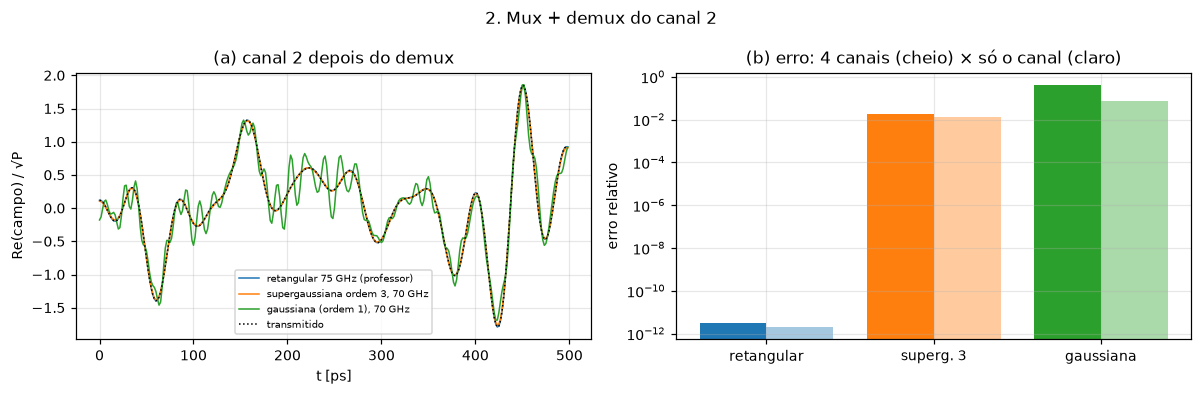

In [3]:
def demux(campo, k, kind, Bf, n):
    """Filtra o canal k e o traz para a banda base."""
    return frequency_shift(apply_optical_filter(campo, bandpass_response(f, OFFS[k], Bf, kind, n)),
                           -OFFS[k], t)

erro = lambda a, b: np.max(np.abs(a - b)) / np.max(np.abs(b))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for i, (nome, (kind, Bf, n)) in enumerate(filtros.items()):
    y = demux(WDM, 1, kind, Bf, n)
    sozinho = demux(multiplex([CANAIS[1]], [OFFS[1]], t), 1, kind, Bf, n)
    ax[0].plot(t[:300] * 1e12, y[0, :300].real / np.sqrt(1e-3), color=C4[i], lw=1, label=nome)
    e_wdm, e_so = erro(y[0], CANAIS[1][0]), erro(sozinho[0], CANAIS[1][0])
    ax[1].bar(i - 0.2, e_wdm, 0.4, color=C4[i])
    ax[1].bar(i + 0.2, e_so, 0.4, color=C4[i], alpha=0.4)
    print(f"{nome}: erro com os 4 canais {e_wdm:.2e} | só o canal 2 {e_so:.2e}")
ax[0].plot(t[:300] * 1e12, CANAIS[1][0, :300].real / np.sqrt(1e-3), "k:", lw=1, label="transmitido")
ax[0].set(xlabel="t [ps]", ylabel="Re(campo) / √P", title="(a) canal 2 depois do demux")
ax[0].legend(fontsize=6.5)
ax[1].set(yscale="log", xticks=range(3), xticklabels=["retangular", "superg. 3", "gaussiana"],
          ylabel="erro relativo", title="(b) erro: 4 canais (cheio) × só o canal (claro)")
fig.suptitle("2. Mux + demux do canal 2")
fig.tight_layout()

**Leitura.** (Números na saída da célula.) Com a máscara retangular o canal volta igual, no
arredondamento (o ~1e-12 vem da fase $2\pi f t$ com $t$ até 109 ns), com ou sem os vizinhos: o
invariante da arquitetura vale para esse filtro e essa guarda. Na supergaussiana de ordem 3 o
erro é quase o mesmo com e sem vizinhos: domina a distorção do próprio canal (as bordas do
espectro de 60 GHz são atenuadas). Na gaussiana de 70 GHz o erro com os vizinhos é seis vezes o do
canal sozinho: ali domina a interferência dos canais vizinhos (seção 3).

## 3. Interferência linear fora da banda

**[Fato: Agrawal, Eq. 6.3.1 e 6.3.4]** A potência que vaza dos vizinhos é
$\sum_n T_{mn}P_n$, e a penalidade é $\delta_X \approx 10\log_{10}(1 + X)$ com
$X = \sum_n T_{mn}$ (potências iguais). **[Dedução]** Para um vizinho n de espectro
$S_n(f)$, $T_{mn} = \int|H(f)|^2S_n(f)df/P_n$: é o que o filtro do canal m deixa passar do
espectro do vizinho.

A medida desliga o canal 2, filtra o campo agregado no canal 2 e mede a potência que sobra.
A previsão integra $|H|^2$ sobre o espectro dos vizinhos.

supergaussiana ordem 3, 70 GHz: X = 1.382e-04 | δ_X = 0.0006 dB
gaussiana, 70 GHz: X = 1.316e-01 | δ_X = 0.5369 dB


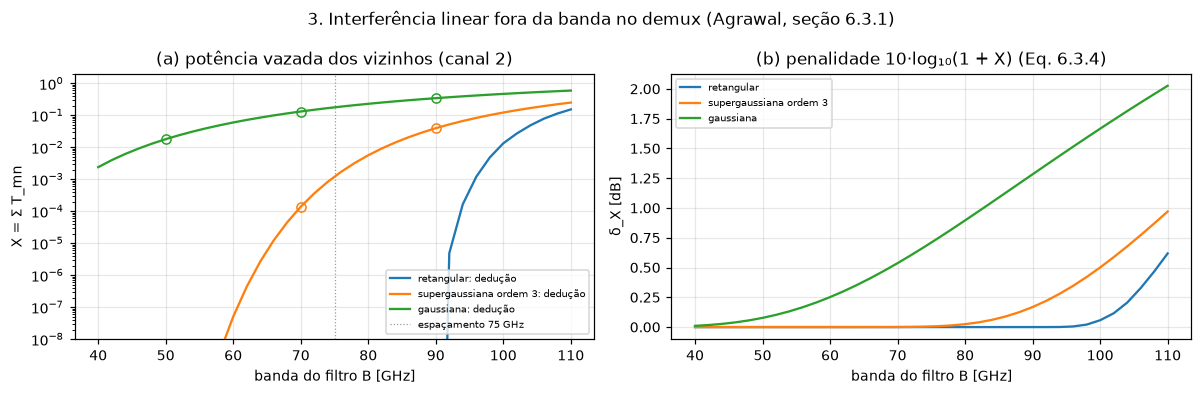

In [4]:
vizinhos = multiplex([c if k != 1 else 0 * c for k, c in enumerate(CANAIS)], OFFS, t)
Sviz = np.sum(np.abs(np.fft.fft(vizinhos, axis=1)) ** 2, axis=0) / N ** 2   # potência por bin
B_eixo = np.linspace(40e9, 110e9, 36)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for i, (kind, n, rot) in enumerate([("rectangular", 1, "retangular"), ("supergaussian", 3, "supergaussiana ordem 3"),
                                    ("supergaussian", 1, "gaussiana")]):
    Xp = [np.sum(np.abs(bandpass_response(f, OFFS[1], Bf, kind, n)) ** 2 * Sviz) / 1e-3 for Bf in B_eixo]
    ax[0].semilogy(B_eixo / 1e9, np.array(Xp) + 1e-30, "-", color=C4[i], label=f"{rot}: dedução")
    Bm = np.array([50e9, 70e9, 90e9])
    Xm = [np.sum(np.mean(np.abs(apply_optical_filter(vizinhos, bandpass_response(f, OFFS[1], Bf, kind, n))) ** 2,
                         axis=1)) / 1e-3 for Bf in Bm]
    ax[0].semilogy(Bm / 1e9, np.array(Xm) + 1e-30, "o", mfc="none", color=C4[i])
    ax[1].plot(B_eixo / 1e9, 10 * np.log10(1 + np.array(Xp)), "-", color=C4[i], label=rot)
ax[0].axvline(75, color="0.6", ls=":", lw=0.8, label="espaçamento 75 GHz")
ax[0].set(ylim=(1e-8, 2), xlabel="banda do filtro B [GHz]", ylabel="X = Σ T_mn",
          title="(a) potência vazada dos vizinhos (canal 2)")
ax[1].set(xlabel="banda do filtro B [GHz]", ylabel="δ_X [dB]",
          title="(b) penalidade 10·log₁₀(1 + X) (Eq. 6.3.4)")
for a_ in ax: a_.legend(fontsize=6.5)
fig.suptitle("3. Interferência linear fora da banda no demux (Agrawal, seção 6.3.1)")
fig.tight_layout()
for kind, n, rot in [("supergaussian", 3, "supergaussiana ordem 3"), ("supergaussian", 1, "gaussiana")]:
    X70 = np.sum(np.abs(bandpass_response(f, OFFS[1], 70e9, kind, n)) ** 2 * Sviz) / 1e-3
    print(f"{rot}, 70 GHz: X = {X70:.3e} | δ_X = {10*np.log10(1+X70):.4f} dB")

**Leitura.** (Números na saída da célula.)
- (a) A potência medida (pontos) coincide com a integral de $|H|^2$ sobre o espectro dos
  vizinhos (linhas). A máscara retangular não deixa passar nada enquanto a borda não alcança o
  espectro do vizinho, que começa a 75 − 30 = 45 GHz do centro do canal: só para B > 90 GHz.
  As suaves vazam gradualmente, e a gaussiana vaza muito mais.
- (b) Com 70 GHz, a supergaussiana de ordem 3 (a do VPI, se a leitura do guia estiver certa) dá
  penalidade desprezível; a gaussiana de ordem 1 dá algumas décimas de dB. O preço da
  supergaussiana estreita é a distorção do próprio canal (seção 2).

Testes: issue #21.